# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

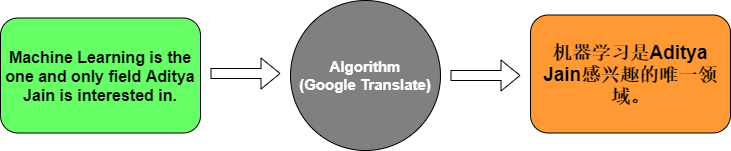

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [1]:
#!pip install tensorflow

In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [3]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [4]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [5]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [6]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 10s 10s/step - accuracy: 0.0000e+00 - loss: 2.4854 - val_accuracy: 0.0000e+00 - val_loss: 2.4866
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.5714 - loss: 2.4770 - val_accuracy: 0.0000e+00 - val_loss: 2.4886
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - accuracy: 0.5714 - loss: 2.4685 - val_accuracy: 0.0000e+00 - val_loss: 2.4908
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step - accuracy: 0.5714 - loss: 2.4594 - val_accuracy: 0.0000e+00 - val_loss: 2.4931
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step - accuracy: 0.5714 - loss: 2.4492 - val_accuracy: 0.0000e+00 - val_loss: 2.4957
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step - accuracy: 0.5714 - loss: 2.4377 - val_accuracy: 0.0000e+00 - val_loss: 2.4986
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step - accuracy: 0.5714 - loss: 2.4244 - val_accuracy: 0.0000e+00 - val_loss: 2.5020
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step - accuracy: 0.5714 - loss: 2.4087 - val_accu

In [7]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 269ms/step
Input: How are you?
Translation: comment ça va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


1. **Embedding:** it takes the word index, which is just a number, and turns it into a dense vector (64 numbers in the example). These values are learned during training, so words used in similar ways end up with similar vectors.

2. **Encoder LSTM:** it reads the English sentence word by word and keeps updating its memory. At the end it gives one fixed-size vector that summarizes the whole sentence.

3. **Decoder LSTM:** it takes that summary vector (RepeatVector copies it once for every output position) and produces an output for each position of the French sentence, so it builds the translation step by step.

4. **Softmax:** it turns the scores of each position into probabilities over all French words, and they add up to 1. Then we can pick the word with the highest probability, and the loss can compare it with the correct word.

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

In [8]:
# check that TensorFlow can see the GPU
print(tf.config.list_physical_devices("GPU"))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Load the data

In [9]:
import pandas as pd

import os

if not os.path.exists("eng_-french.csv"):
    from google.colab import files
    files.upload()  # choose eng_-french.csv

df = pd.read_csv("eng_-french.csv")
df.columns = ["english", "french"]
print(df.shape)
print(df.isna().sum())
df.sample(5, random_state=1)

Saving eng_-french.csv to eng_-french.csv
(175621, 2)
english    0
french     0
dtype: int64


,english,french
37931,Tom checked the date.,Tom a vérifié la date.
142019,That TV station broadcasts only movies.,Cette chaîne de télévision diffuse uniquement ...
63699,Tell me what I did wrong.,Dites-moi ce que j'ai fait de travers !
37669,They want more space.,Ils veulent plus d'espace.
165392,"If I had more money, I could move to a bigger ...","Si j'avais davantage d'argent, je pourrais dém..."


### Pre-processing

The full dataset has 175,621 pairs and some sentences are more than 40 words, which would take too long to train. So I only kept short sentences (up to 6 English words and 8 French words) and took a random sample of 30,000 pairs.

In [10]:
df = df.drop_duplicates()
short = df[(df["english"].str.split().str.len() <= 6) & (df["french"].str.split().str.len() <= 8)]
print("Short pairs:", len(short))

data = short.sample(30000, random_state=42)

eng_train_txt, eng_test_txt, frn_train_txt, frn_test_txt = train_test_split(
    data["english"].tolist(), data["french"].tolist(), test_size=0.1, random_state=42)
print(len(eng_train_txt), len(eng_test_txt))

Short pairs: 106204
27000 3000


In [11]:
# tokenizers are fit on the training data only, unknown test words become <unk>
eng_tok = Tokenizer(oov_token="<unk>")
eng_tok.fit_on_texts(eng_train_txt)

frn_tok = Tokenizer(oov_token="<unk>")
frn_tok.fit_on_texts(frn_train_txt)

eng_vocab = len(eng_tok.word_index) + 1
frn_vocab = len(frn_tok.word_index) + 1
print("English vocab:", eng_vocab, " French vocab:", frn_vocab)

eng_len = max(len(s) for s in eng_tok.texts_to_sequences(eng_train_txt))
frn_len = max(len(s) for s in frn_tok.texts_to_sequences(frn_train_txt))
print("Max lengths:", eng_len, frn_len)

# padding at the end for both, the GPU LSTM only supports masks with right padding
X_train = pad_sequences(eng_tok.texts_to_sequences(eng_train_txt), maxlen=eng_len, padding="post", truncating="post")
X_test = pad_sequences(eng_tok.texts_to_sequences(eng_test_txt), maxlen=eng_len, padding="post", truncating="post")
y_train = pad_sequences(frn_tok.texts_to_sequences(frn_train_txt), maxlen=frn_len, padding="post", truncating="post")
y_test = pad_sequences(frn_tok.texts_to_sequences(frn_test_txt), maxlen=frn_len, padding="post", truncating="post")

print(X_train.shape, y_train.shape)

English vocab: 6436  French vocab: 11608
Max lengths: 7 10
(27000, 7) (27000, 10)


### Build the model

Same structure as the example in the lab, just with bigger layers because the vocabulary is much bigger.

In [12]:
tf.keras.utils.set_random_seed(42)

mt_model = tf.keras.Sequential([
    tf.keras.Input(shape=(eng_len,)),
    tf.keras.layers.Embedding(input_dim=eng_vocab, output_dim=128, mask_zero=True),
    tf.keras.layers.LSTM(256),
    tf.keras.layers.RepeatVector(frn_len),
    tf.keras.layers.LSTM(256, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(frn_vocab, activation="softmax"))
])

mt_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
mt_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 7, 128)         │       823,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 256)            │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_1 (RepeatVector)  │ (None, 10, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 10, 256)        │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_1              │ (None, 10, 11608)      │     2,983,256 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,726,616 (18.03 MB)

 Trainable params: 4,726,616 (18.03 MB)

 Non-trainable params: 0 (0.00 B)

### Train

In [13]:
early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

history = mt_model.fit(X_train, np.expand_dims(y_train, -1), epochs=25, batch_size=64,
                       validation_split=0.1, callbacks=[early_stop], verbose=2)

Epoch 1/25
380/380 - 16s - 42ms/step - accuracy: 0.4882 - loss: 4.2152 - val_accuracy: 0.4980 - val_loss: 3.8354
Epoch 2/25
380/380 - 13s - 33ms/step - accuracy: 0.5072 - loss: 3.6404 - val_accuracy: 0.5089 - val_loss: 3.6778
Epoch 3/25
380/380 - 13s - 34ms/step - accuracy: 0.5165 - loss: 3.5133 - val_accuracy: 0.5125 - val_loss: 3.6113
Epoch 4/25
380/380 - 13s - 34ms/step - accuracy: 0.5206 - loss: 3.4319 - val_accuracy: 0.5164 - val_loss: 3.5257
Epoch 5/25
380/380 - 13s - 35ms/step - accuracy: 0.5319 - loss: 3.3090 - val_accuracy: 0.5284 - val_loss: 3.4269
Epoch 6/25
380/380 - 13s - 34ms/step - accuracy: 0.5434 - loss: 3.1814 - val_accuracy: 0.5380 - val_loss: 3.3456
Epoch 7/25
380/380 - 13s - 34ms/step - accuracy: 0.5525 - loss: 3.0631 - val_accuracy: 0.5441 - val_loss: 3.2617
Epoch 8/25
380/380 - 13s - 34ms/step - accuracy: 0.5585 - loss: 2.9510 - val_accuracy: 0.5500 - val_loss: 3.1985
Epoch 9/25
380/380 - 13s - 35ms/step - accuracy: 0.5689 - loss: 2.8419 - val_accuracy: 0.5616 - 

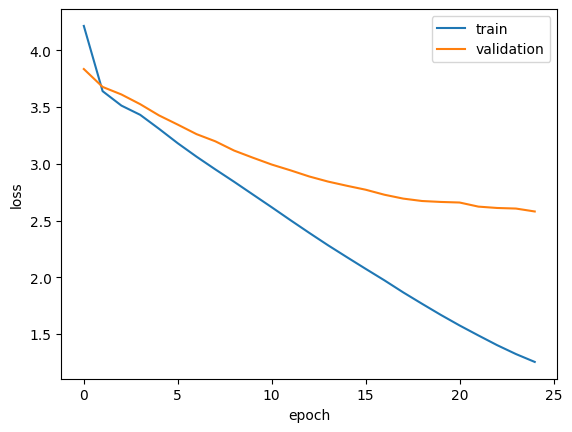

In [14]:
import matplotlib.pyplot as plt

plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.show()

### Evaluate

Most French sentences are shorter than the max length, so a lot of positions are just padding. Counting those makes the accuracy look better than it is, so I also calculated the accuracy on the real words only, and the BLEU score.

In [15]:
loss, acc = mt_model.evaluate(X_test, np.expand_dims(y_test, -1), verbose=0)
print(f"Test loss: {loss:.4f}")
print(f"Keras test accuracy: {acc:.4f}")

pred_ids = np.argmax(mt_model.predict(X_test, verbose=0), axis=-1)
real_words = y_test != 0
word_acc = (pred_ids[real_words] == y_test[real_words]).mean()
print(f"Accuracy on real words only: {word_acc:.4f}")

Test loss: 2.5334
Keras test accuracy: 0.6282
Accuracy on real words only: 0.3047


In [16]:
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

# skip index 0 (padding), otherwise the tokenizer turns it into <unk>
def ids_to_words(ids):
    return [frn_tok.index_word[i] for i in ids if i != 0]

hyps = [ids_to_words(ids) for ids in pred_ids]
refs = [[ids_to_words(ids)] for ids in y_test]

bleu = corpus_bleu(refs, hyps, smoothing_function=SmoothingFunction().method1)
print(f"BLEU score: {bleu:.4f}")

BLEU score: 0.0929


### Try translations

In [17]:
def translate(sentence):
    seq = pad_sequences(eng_tok.texts_to_sequences([sentence]), maxlen=eng_len, padding="post", truncating="post")
    ids = np.argmax(mt_model.predict(seq, verbose=0), axis=-1)
    return ' '.join(ids_to_words(ids[0]))

# sentences from the test set
for i in range(10):
    print("EN  :", eng_test_txt[i])
    print("REAL:", frn_test_txt[i])
    print("PRED:", translate(eng_test_txt[i]))
    print()

EN  : I know what my choices are.
REAL: Je sais quels sont mes choix.
PRED: je sais que c'est de de

EN  : I have a tourist visa.
REAL: J'ai un visa de tourisme.
PRED: j'ai un visa touristique

EN  : It can't possibly work.
REAL: Il est impossible que cela fonctionne.
PRED: ça ne pas pas de de

EN  : That's what I love about Tom.
REAL: C'est ce que j'adore chez Tom.
PRED: c'est ce que que j'ai tom

EN  : Time has come to get serious.
REAL: Le temps est venu d'être sérieux.
PRED: cela y a t il

EN  : The mass is over.
REAL: La messe est dite.
PRED: le manteau est

EN  : Rome is in Italy.
REAL: Rome est en Italie.
PRED: est est est est en

EN  : Where were you today?
REAL: Où étiez-vous aujourd'hui ?
PRED: où vous tu

EN  : Your office is nicer than mine.
REAL: Ton bureau est plus beau que le mien.
PRED: votre mère est est que que que santé

EN  : No one knew who did it.
REAL: Personne ne savait qui l'avait commis.
PRED: personne ne a tom qui



In [18]:
# sentences like the company would need
for s in ["This phone is very good.", "The price is too high.", "I love this product.", "Where is my order?", "The shipping was fast."]:
    print(s, "-->", translate(s))

This phone is very good. --> ce est est très
The price is too high. --> le est est trop ingénieux
I love this product. --> j'adore cette tom
Where is my order? --> où est votre tronçonneuse
The shipping was fast. --> le un impressionnant


### Results

In [19]:
print(f"Epochs trained: {len(history.history['loss'])}")
print(f"Keras test accuracy: {acc:.4f}")
print(f"Accuracy on real words only: {word_acc:.4f}")
print(f"BLEU score: {bleu:.4f}")

Epochs trained: 25
Keras test accuracy: 0.6282
Accuracy on real words only: 0.3047
BLEU score: 0.0929


### Discussion

The model trained for all 25 epochs on the Colab T4 GPU. Early stopping never triggered because the validation loss was still going down at the last epoch (2.58), so more epochs might improve it a little. There is also a clear gap between training and validation by the end (loss 1.25 vs 2.58, accuracy 0.72 vs 0.62), so it is starting to overfit.

The Keras test accuracy is 62.8%, but this number is misleading because it counts the padding. On the real words only the accuracy is 30.5%, and the BLEU score is 0.093, which is low. These two numbers show the real performance better.

The translations match this. Short and common sentences come out close, for example "I have a tourist visa." gave "j'ai un visa touristique", which is correct even though it isn't the same as the reference. In longer sentences the model repeats words ("est est est est en" for "Rome is in Italy.") or stops early. The start of the sentence is usually better than the end, like "je sais que c'est de de".

The e-commerce sentences were the weakest. "Where is my order?" gave "où est votre tronçonneuse", and "I love this product." gave "j'adore cette tom". The start is right but the important word is wrong, because the training data is general sentences and not shopping text. So this model is not good enough for the company to translate listings or reviews, and it only works as a simple baseline.

### Limitations

- The model was trained only on short general sentences, not on real product listings or customer reviews, so the company would need data from its own domain.
- The encoder squeezes the whole sentence into one vector and the decoder never sees the words it already predicted. This makes it hard to handle longer sentences.
- Words outside the training vocabulary become `<unk>`, which is a problem for product and brand names.
- An attention model or a pre-trained transformer such as MarianMT would be more suitable for a real company.